In [1]:
# Show all outputs of a cell in a jupyter notebook
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [2]:
# Import PyTorch and Torchvision
import torch, torchvision

###Q1.
Mount Google Drive to Colab.

In [3]:
# Mount Google drive to colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


###Q2.
Read the csv file 'dataset-chns-2006-subset3.csv' into a Pandas DataFrame. You may use the read_csv() function: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html

In [5]:
import pandas as pd

data_path = '/content/drive/MyDrive/school/26 Fall/Practical Artificial Intelligence and Applications - 982026 - 916 AM/Assignments/dataset-chns-2006-subset3.csv'
df = pd.read_csv(data_path)

###Q3.
Show the first five observations of the DataFrame. You may use the head() function.

In [6]:
df.head()

,age,gender,systolic,diastolic,weight
0,27,1,128,84,83.0
1,60,1,110,68,70.0
2,38,1,118,80,63.2
3,65,1,138,80,78.2
4,64,1,130,90,77.0


###Q4.
Show describle statistics of the features in the DataFrame. You may use the describe() function.

In [7]:
df.describe()

,age,gender,systolic,diastolic,weight
count,9178.000000,9178.000000,9178.000000,9178.000000,9178.000000
mean,49.077795,1.529963,121.793746,78.848878,60.746383
std,15.188060,0.499129,18.140981,11.120691,12.788114
min,17.000000,1.000000,70.000000,40.000000,19.000000
25%,38.000000,1.000000,110.000000,70.000000,52.000000
50%,49.000000,2.000000,120.000000,80.000000,59.800000
75%,59.750000,2.000000,130.000000,84.000000,67.000000
max,95.000000,2.000000,240.000000,180.000000,169.000000


###Q5.
Create two PyTorch tensors, one for body weight, and the other for systolic blood pressure. Body weight will serve as the independent variable, and systolic blood pressure will serve as the dependent variable. Note: you may need to change the dtype of systolic blood pressure from int to float.

In [8]:
import torch

x = torch.tensor(df['weight'].tolist(), dtype = torch.float32)
y = torch.tensor(df['systolic'].tolist(), dtype = torch.float32)

###Q6.
Standardize the two tensors so that they have mean of zero and standard devision of one.

In [9]:
x = (x - x.mean()) / x.std()
y = (y - y.mean()) / y.std()

###Q7.
Randomly shuffle and split train and validation set indices. Keep 80% of data in the train set and the other 20% in the validation set.

In [10]:
from sklearn.model_selection import train_test_split

train_indices, val_indices = train_test_split(
    range(len(x)),
    test_size = 0.2,
    random_state = 42
)

###Q8.
Used the train and validation indices to split the dataset into train set and validation set.

In [11]:
x_train = x[train_indices]
y_train = y[train_indices]
x_val = x[val_indices]
y_val = y[val_indices]

###Q9.
Define the model, which takes the form of
```
w * x + b
```
in which w and b are weight and bias, respectively; and x is your only independent variable.

In [12]:
def model(x, w, b):
    return w * x + b

###Q10.
Define your loss funtion, which takes the form of
```
(y_predicted - y)**2
```
in which y is your dependent variable, and y_predicted in the predicted dependent variable from the model.

In [17]:
def loss_fn(y_predicted, y):
    squared_diffs = (y_predicted - y)**2
    return squared_diffs.mean()

###Q11.
Define the training loop. The training loop will take the following arguments:
* n_epochs: number of epochs to run
* optimizer: optimizer
* params: a tensor containing the initial values for weight and bias
* x_train: body weight in the train set
* y_train: systolic blood pressure in the train set
* x_val: body weight in the validation set
* y_val: systolic blood pressure in the validation set

\
Hints:
* Remember to use with torch.no_grad() because you do not want gradients to cumulate on validation loss
* Remember to use optimizer.zero_grad() to zero the gradients after each run
* Use backward() function for backpropagation
* Create two lists to store the train and validation loss over epochs

In [15]:
def training_loop(n_epochs, optimizer, params,
                  x_train, y_train, x_val, y_val):

    loss_train_lst, loss_val_lst = [], []

    for epoch in range(1, n_epochs + 1):

        y_train_predicted = model(x_train, *params)
        loss_train = loss_fn(y_train_predicted, y_train)

        with torch.no_grad():
            y_val_predicted = model(x_val, *params)
            loss_val = loss_fn(y_val_predicted, y_val)

        # Clear gradients from the previous epoch
        optimizer.zero_grad()

        # Calculate gradients using training loss
        loss_train.backward()

        # Update weight and bias
        optimizer.step()

        # Save this epoch's losses
        loss_train_lst.append(loss_train.item())
        loss_val_lst.append(loss_val.item())

        # Print selected results
        if epoch in {1, 2, 3, 10, 11, 99, 100, 500, 1000, 5000}:
          print('Epoch %d, Train Loss %f, Val Loss %f' % (epoch, float(loss_train), float(loss_val)))
          print('    Params:', params)
          print('    Grad:  ', params.grad)
        # Break the loop if we get infinite value for the loss function
        if not torch.isfinite(loss_train).all():
          break

    return loss_train_lst, loss_val_lst

###Q12.
Invoke the training loop. Set the following parameters:
```
params = torch.tensor([1.0, 0.0], requires_grad = True)
learning_rate = 0.05
n_epochs = 100
optimizer = optim.SGD([params], lr = learning_rate)
```

In [18]:
from torch import optim

params = torch.tensor([1.0, 0.0], requires_grad = True)
learning_rate = 0.05
n_epochs = 100
optimizer = optim.SGD([params], lr = learning_rate)

loss_train_lst, loss_val_lst = training_loop(
    n_epochs, optimizer, params,
    x_train, y_train, x_val, y_val
)

Epoch 1, Train Loss 1.575201, Val Loss 1.546589
    Params: tensor([ 9.2183e-01, -3.6173e-04], requires_grad=True)
    Grad:   tensor([1.5635, 0.0072])
Epoch 2, Train Loss 1.459052, Val Loss 1.428281
    Params: tensor([ 8.5142e-01, -6.9702e-04], requires_grad=True)
    Grad:   tensor([1.4080, 0.0067])
Epoch 3, Train Loss 1.364849, Val Loss 1.332434
    Params: tensor([ 0.7880, -0.0010], requires_grad=True)
    Grad:   tensor([1.2681, 0.0062])
Epoch 10, Train Loss 1.053836, Val Loss 1.017502
    Params: tensor([ 0.4896, -0.0026], requires_grad=True)
    Grad:   tensor([0.6093, 0.0036])
Epoch 11, Train Loss 1.036198, Val Loss 0.999820
    Params: tensor([ 0.4622, -0.0028], requires_grad=True)
    Grad:   tensor([0.5487, 0.0033])
Epoch 99, Train Loss 0.960487, Val Loss 0.926152
    Params: tensor([ 0.2137, -0.0046], requires_grad=True)
    Grad:   tensor([5.4617e-05, 9.4739e-07])
Epoch 100, Train Loss 0.960487, Val Loss 0.926152
    Params: tensor([ 0.2137, -0.0046], requires_grad=True)


/tmp/ipykernel_3577/2034706297.py:30: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print('Epoch %d, Train Loss %f, Val Loss %f' % (epoch, float(loss_train), float(loss_val)))


###Q13.
Report the estimated weight and bias.

In [19]:
w, b = params.detach()

print('Estimated weight:', w.item())
print('Estimated bias:', b.item())

Estimated weight: 0.21369868516921997
Estimated bias: -0.00459630461409688


###Q14.
Plot train and validation loss across epochs in a single figure.

Text(0.5, 0, 'Epoch')

Text(0, 0.5, 'Mean squared error')

Text(0.5, 1.0, 'Training and Validation Loss')

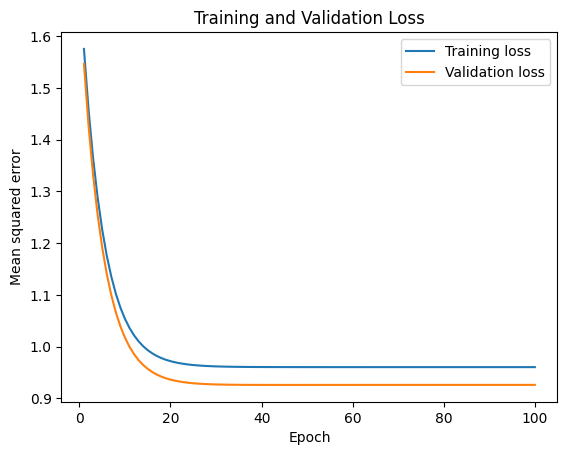

In [20]:
import matplotlib.pyplot as plt

epochs = range(1, len(loss_train_lst) + 1)

plt.plot(epochs, loss_train_lst, label = 'Training loss')
plt.plot(epochs, loss_val_lst, label = 'Validation loss')

plt.xlabel('Epoch')
plt.ylabel('Mean squared error')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

###Q15.
Compare the estimated weight and bias with a linear regression estimate. You can run a linear regression using the famous sklearn module.

Hint:
```
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
```

In [21]:
from sklearn.linear_model import LinearRegression

# Convert tensors to NumPy arrays
X_train = x_train.detach().numpy().reshape(-1, 1)
Y_train = y_train.detach().numpy()

# Fit linear regression
lr = LinearRegression()
lr.fit(X_train, Y_train)


LinearRegression()

In [22]:
# Compare coefficients
print('PyTorch weight:', params[0].item())
print('Linear regression weight:', lr.coef_[0])

print('PyTorch bias:', params[1].item())
print('Linear regression intercept:', lr.intercept_)

PyTorch weight: 0.21369868516921997
Linear regression weight: 0.21367638
PyTorch bias: -0.00459630461409688
Linear regression intercept: -0.0045967274
